# SOFIE EV microgrid: a visual guide to the data

**Goal.** By the end of this notebook, you should know what is in the dataset, when each signal is available, what the main patterns look like, and which conclusions the data cannot support.

SOFIE is one islanded EV charging site with solar panels, a battery, and **eight wallboxes**. The downloaded file is a historical JSON export, not a live feed. This notebook uses the project's checked and cleaned **minute-level replay tables** for most charts. They come only from that JSON file. We never change the raw file.

**Read this first**

- A **minute** is one row of site readings or one wallbox reading during that recorded minute. It is not necessarily one sample.
- **kW** means power at a moment. **kWh** means energy accumulated over time. We do not call a power reading “energy.”
- A blank value means **unknown**, not zero. This is especially important for solar and chargers.
- The source timestamps do not say which time zone they use. Charts use the **recorded clock**. The application currently interprets that clock as UTC, but this is an assumption.
- To run from a fresh checkout: place the pinned raw file at `data/raw/`, run `make setup`, then `make ingest`, and open this notebook with the project's Python kernel.

## 1. Where the numbers come from

The large JSON export contains eight source tables. The replay builder checks and summarizes them into six smaller CSV tables. The table below is a map, not eight independent datasets.

| Raw table | What it holds | Used here? |
|:--|:--|:--|
| `logging` | Site electrical readings, solar output, battery state and temperature | Yes, through `microgrid_minute` |
| `charge_box` | Wallbox inventory | Yes, through `wallbox` |
| `connector` | Connector-to-wallbox links | Used by the replay builder |
| `connector_meter_value` | Meter readings, including charger power | Yes, through `charger_minute` |
| `connector_status` | Events such as Charging or Faulted | Yes, through `connector_event` |
| `transaction_start` | Session starts | Yes, through `charging_session` |
| `transaction_stop` | Session stops | Yes, through `charging_session` |
| `scn_values` | Charging-network current values | Validated, but not used in these charts |

The code below verifies the exact raw file and reads the current replay generation. A changed or missing source will stop the notebook rather than quietly mix datasets.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "config/telemetry-source.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the EV microgrid project.")
sys.path.insert(0, str(ROOT))

from backend.configuration.dataset import SOURCE_CONTRACT, derived_path, raw_path
from backend.ingestion.value_conversion import sha256
from backend.telemetry.repository import replay_store

assert raw_path().is_file(), "The pinned raw JSON is missing. See notebooks/README.md."
assert sha256(raw_path()) == SOURCE_CONTRACT["sha256"], "The raw JSON does not match the pinned file."
with replay_store() as store:
    meta = dict(store.metadata)
    generation_dir = store.directory
    table_manifest = dict(store.files)

assert meta["source_sha256"] == SOURCE_CONTRACT["sha256"]
plt.rcParams.update({"figure.dpi": 115, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
NAVY, TEAL, GOLD, RED, BLUE = "#1d3557", "#2a9d8f", "#e9a23b", "#d65a5a", "#457b9d"

display(Markdown(
    f"**Source verified.** Recorded observations run from **{meta['first_raw']}** to "
    f"**{meta['last_raw']}**. The source filename says June 30, but the last site "
    f"reading is June 29. The replay has **{int(meta['wallbox_count'])} wallboxes**. "
    f"Source SHA-256: `{meta['source_sha256']}`."
))

**Source verified.** Recorded observations run from **2025-12-01 00:00:02** to **2026-06-29 23:59:57**. The source filename says June 30, but the last site reading is June 29. The replay has **8 wallboxes**. Source SHA-256: `3aec010bc9b592652ed4528c2712124630eef3a31f31e3189c04f227cc7b1428`.

### The six replay tables

A row in `microgrid_minute` is one site minute. A row in `charger_minute` is **one wallbox in one minute**; several wallboxes can share the same minute. `connector_event` rows are changes of state, not a continuous status history. `charging_session` joins known starts and stops. `quality_check` lists issues the builder found.

In [2]:
TABLE_MEANING = {
    "microgrid_minute": "Site solar and battery readings, grouped by minute",
    "charger_minute": "Reported power for one wallbox in one minute",
    "wallbox": "Wallbox inventory",
    "connector_event": "Status changes and error codes",
    "charging_session": "Matched charging starts and stops",
    "quality_check": "Checks and known data issues",
}
table_overview = pd.DataFrame([
    {"Replay table": name, "Rows": info["rows"], "Meaning": TABLE_MEANING[name]}
    for name, info in table_manifest.items()
]).sort_values("Replay table")
display(table_overview.style.format({"Rows": "{:,}"}).hide(axis="index"))

Replay table,Rows,Meaning
charger_minute,"420,984",Reported power for one wallbox in one minute
charging_session,944,Matched charging starts and stops
connector_event,"36,421",Status changes and error codes
microgrid_minute,"300,617","Site solar and battery readings, grouped by minute"
quality_check,8,Checks and known data issues
wallbox,8,Wallbox inventory


## 2. The fields used in this notebook

These units matter when reading the charts. The replay builder converts raw values before we load them.

| Replay field | Plain meaning | Unit and source conversion |
|:--|:--|:--|
| `solar_kw` | Solar power sent out by the PV system | kW; raw `logging.p_actual` in W ÷ 1,000 |
| `battery_soc_pct` | How full the battery is (state of charge, or SoC) | %; raw `bat_soc` |
| `battery_temp_c` | Battery temperature | °C; raw `bat_temp` in tenths of °C ÷ 10 |
| `power_kw` | Power reported by an EV wallbox | kW; `Power.Active.Import` in W ÷ 1,000, for connector ID 1 |
| `sample_count` | Number of raw readings combined into that minute | count; more samples do not mean more minutes |
| `solar_samples` | Number of solar readings available in that minute | count; zero means no known solar value |
| `p_sum_kw` | Another site power field | kW, but its physical sign and meaning are unresolved; **not used as grid power** |

The site is described as having a **38.4 kWh battery** and an **18 kW maximum battery power**. Those are site descriptions, not extra measured columns. We do not turn missing wallbox readings into zero demand, and we do not calculate a full site energy balance from these fields.

In [3]:
# CSVs are already the validated replay generation. Read them with pandas for exploration.
minute = pd.read_csv(generation_dir / "microgrid_minute.csv", parse_dates=["raw_minute"])
charger = pd.read_csv(generation_dir / "charger_minute.csv", parse_dates=["raw_minute"])
wallbox = pd.read_csv(generation_dir / "wallbox.csv")
event = pd.read_csv(generation_dir / "connector_event.csv", parse_dates=["raw_timestamp"])
session = pd.read_csv(generation_dir / "charging_session.csv",
                      parse_dates=["start_raw", "stop_raw"])
quality = pd.read_csv(generation_dir / "quality_check.csv")

for name, frame in {"microgrid_minute": minute, "charger_minute": charger,
                    "wallbox": wallbox, "connector_event": event,
                    "charging_session": session, "quality_check": quality}.items():
    assert len(frame) == table_manifest[name]["rows"], f"Unexpected row count: {name}"
minute = minute.sort_values("raw_minute").reset_index(drop=True)
charger = charger.sort_values(["raw_minute", "wallbox_id"]).reset_index(drop=True)

display(Markdown("**One site-minute row:**"))
display(minute.head(1).T.rename(columns={0: "Example value"}))
display(Markdown("**One wallbox-minute row:**"))
display(charger.head(1).T.rename(columns={0: "Example value"}))
display(Markdown("**Wallbox inventory:**"))
display(wallbox.sort_values("id").style.hide(axis="index"))

**One site-minute row:**

,Example value
raw_minute,2025-12-01 00:00:00
sample_count,12
solar_kw,NaN
solar_samples,0
battery_soc_pct,45.0
battery_temp_c,12.3
p_sum_kw,0.01
soc_bad_samples,0
solar_bad_samples,0


**One wallbox-minute row:**

,Example value
raw_minute,2025-12-01 03:15:00
wallbox_id,WB1
power_kw,0.0
sample_count,1
last_raw_timestamp,2025-12-01 03:15:00


**Wallbox inventory:**

id,vendor,model,firmware
WB1,Alfen BV,NG910-60583,7.3.0-4377
WB2,Alfen BV,NG910-60583,7.3.0-4377
WB3,Alfen BV,NG910-60583,7.3.0-4377
WB4,Alfen BV,NG910-60583,7.3.0-4377
WB5,Alfen BV,NG910-60583,7.3.0-4377
WB6,Alfen BV,NG910-60583,7.3.0-4377
WB7,Alfen BV,NG910-60583,7.3.0-4377
WB8,Alfen BV,NG910-60583,7.3.0-4377


## 3. How much time is covered?

The site should have one row for every minute between its first and last recorded site minute. We compare that expected timeline with the rows actually present. A missing **site minute** is different from a present minute with a missing **solar value**.

For solar, missingness often happens at night. A missing solar value still does **not** prove that power was zero. Month-to-month changes in the percentage of available solar readings partly reflect day length, so that percentage alone is not sensor uptime.

There are **300,617 site minutes** across **210 calendar days**. That is **98.9%** of the 303,840 minutes in the first-to-last range. Solar has a known value in **158,081 site minutes (52.6% of present site minutes).** There are **no site readings on 21 Jun 2026**.

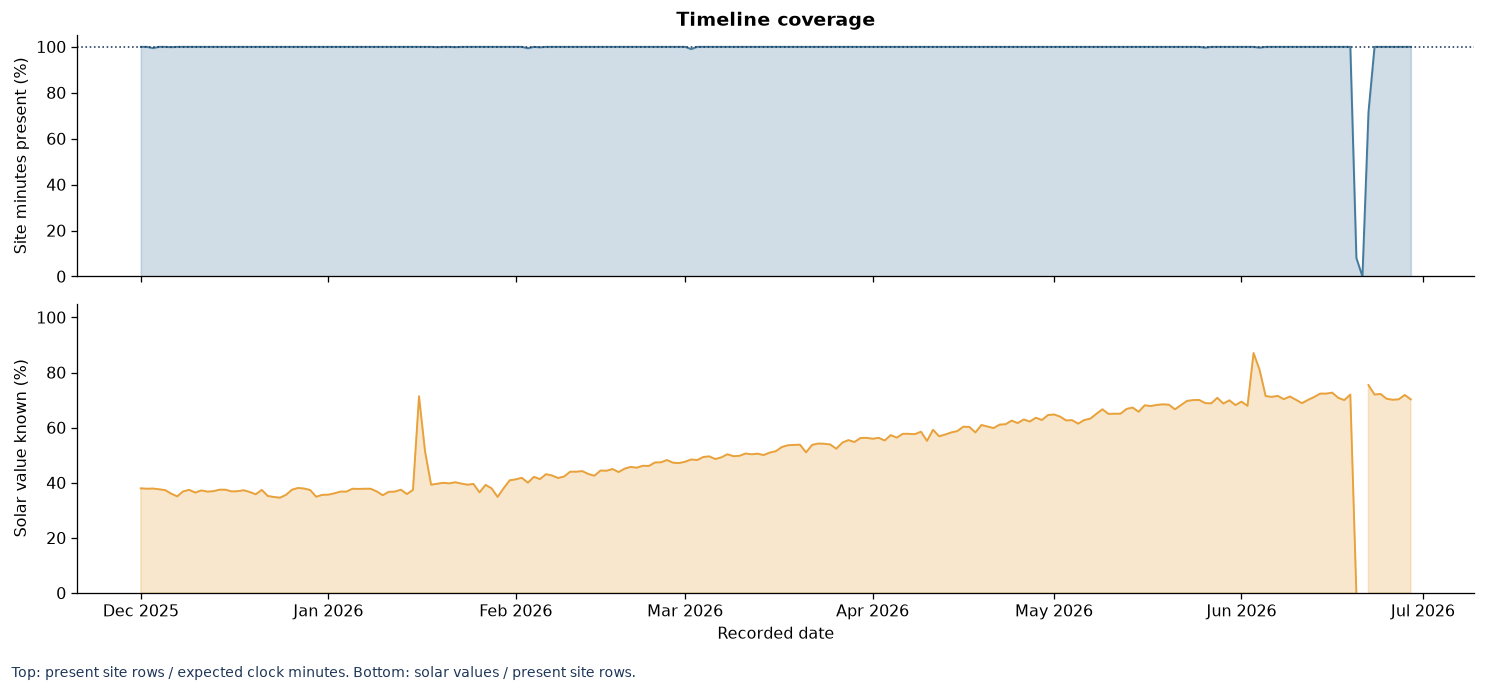

In [4]:
full_clock = pd.date_range(minute.raw_minute.min(), minute.raw_minute.max(), freq="min")
coverage = pd.DataFrame(index=full_clock).join(minute.set_index("raw_minute")[["sample_count", "solar_kw"]])
coverage["day"] = coverage.index.floor("D")
daily = coverage.groupby("day").agg(
    expected_minutes=("sample_count", "size"),
    site_minutes=("sample_count", "count"),
    solar_minutes=("solar_kw", "count"),
)
daily["site_pct"] = 100 * daily.site_minutes / daily.expected_minutes
daily["solar_pct_of_site"] = 100 * daily.solar_minutes / daily.site_minutes.replace(0, np.nan)

site_pct = 100 * len(minute) / len(full_clock)
missing_days = daily.index[daily.site_minutes.eq(0)]
missing_day_text = (" There are **no site readings on " + ", ".join(d.strftime("%d %b %Y") for d in missing_days) + "**.") if len(missing_days) else ""
solar_pct = 100 * minute.solar_kw.notna().mean()
display(Markdown(
    f"There are **{len(minute):,} site minutes** across **{minute.raw_minute.dt.date.nunique():,} "
    f"calendar days**. That is **{site_pct:.1f}%** of the {len(full_clock):,} minutes in the "
    f"first-to-last range. Solar has a known value in **{minute.solar_kw.notna().sum():,} "
    f"site minutes ({solar_pct:.1f}% of present site minutes).**"
    + missing_day_text
))

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True, height_ratios=[1, 1.2])
axes[0].fill_between(daily.index, daily.site_pct, color=BLUE, alpha=.25)
axes[0].plot(daily.index, daily.site_pct, color=BLUE, lw=1.2)
axes[0].set(ylabel="Site minutes present (%)", ylim=(0, 105), title="Timeline coverage")
axes[0].axhline(100, color=NAVY, ls=":", lw=1)
axes[1].fill_between(daily.index, daily.solar_pct_of_site, color=GOLD, alpha=.25)
axes[1].plot(daily.index, daily.solar_pct_of_site, color=GOLD, lw=1.2)
axes[1].set(ylabel="Solar value known (%)", xlabel="Recorded date", ylim=(0, 105))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.text(.01, .01, "Top: present site rows / expected clock minutes. Bottom: solar values / present site rows.",
         fontsize=9, color=NAVY)
fig.tight_layout(rect=(0, .035, 1, 1))
plt.show()

### A compact coverage map

Each square below is one recorded day and hour. Darker squares mean more solar values were present **within site minutes that existed**. The repeated day/night shape is useful context for every solar chart that follows. **Gray** means the site has no row in that day and hour.

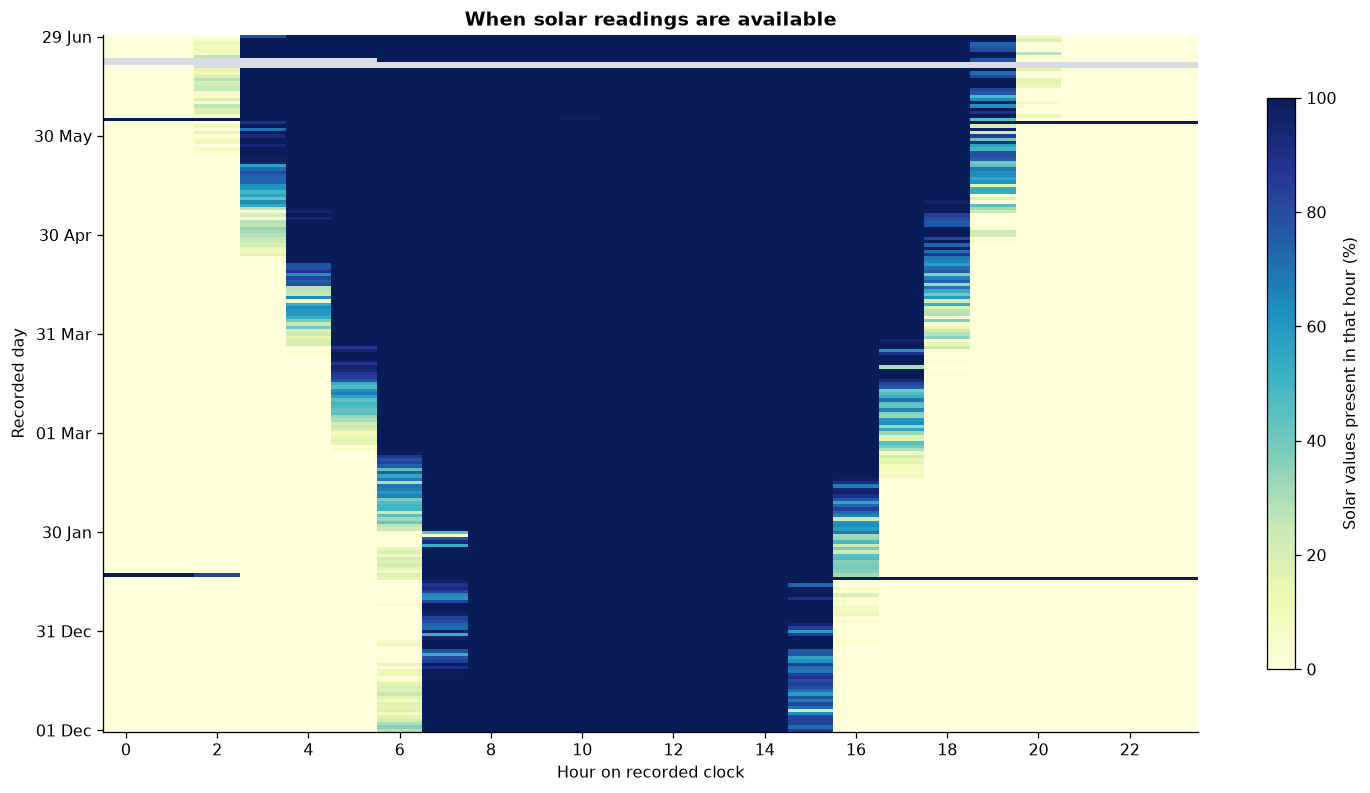

In [5]:
solar_hour = minute.assign(day=minute.raw_minute.dt.floor("D"), hour=minute.raw_minute.dt.hour)
solar_hour = solar_hour.groupby(["day", "hour"]).solar_kw.apply(lambda s: 100 * s.notna().mean())
coverage_map = solar_hour.unstack("hour").reindex(index=daily.index, columns=range(24))
coverage_cmap = plt.colormaps["YlGnBu"].copy()
coverage_cmap.set_bad("#d9dce2")  # Gray means the site minute itself is absent.
fig, ax = plt.subplots(figsize=(13, 7))
im = ax.imshow(np.ma.masked_invalid(coverage_map.to_numpy()), aspect="auto",
               interpolation="nearest", vmin=0, vmax=100, cmap=coverage_cmap, origin="lower")
ax.set(title="When solar readings are available", xlabel="Hour on recorded clock", ylabel="Recorded day")
ax.set_xticks(range(0, 24, 2), range(0, 24, 2))
positions = np.linspace(0, len(coverage_map)-1, 8, dtype=int)
ax.set_yticks(positions, [coverage_map.index[i].strftime("%d %b") for i in positions])
fig.colorbar(im, ax=ax, label="Solar values present in that hour (%)", shrink=.82)
fig.tight_layout()
plt.show()

## 4. Solar power: size, timing, and missing values

The solar charts use only minutes with a recorded solar value. This avoids changing unknown readings into zero. The left chart answers **“how large are the known readings?”** The right chart answers **“at what recorded hour is solar power highest on average?”**

These are descriptions of the historical observations, not a forecast or a statement about the PV system's rated capacity.

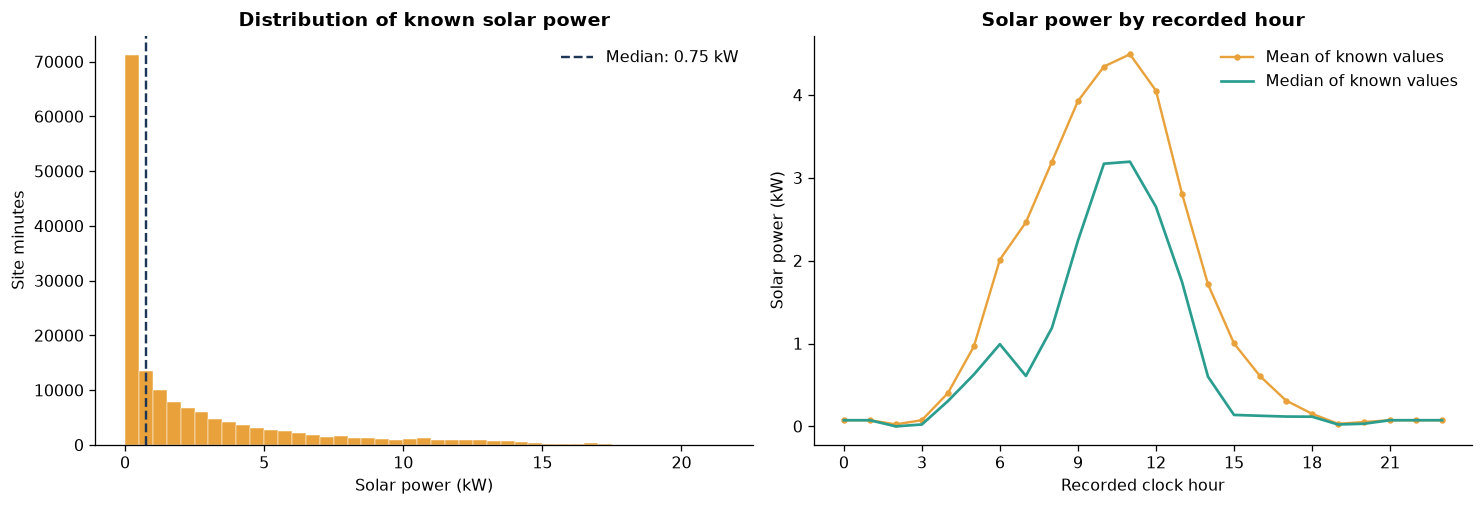

The **median known solar reading is 0.75 kW**; the largest minute average is **20.00 kW**. There are **6,393 known zero minutes**. A known zero and a missing reading are different things.

In [6]:
solar = minute.solar_kw.dropna()
solar_by_hour = minute.groupby(minute.raw_minute.dt.hour).solar_kw.agg(["mean", "median", "count"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(solar, bins=np.arange(0, max(21, np.ceil(solar.max()) + 1), .5),
             color=GOLD, edgecolor="white", linewidth=.3)
axes[0].axvline(solar.median(), color=NAVY, ls="--", label=f"Median: {solar.median():.2f} kW")
axes[0].set(title="Distribution of known solar power", xlabel="Solar power (kW)", ylabel="Site minutes")
axes[0].legend(frameon=False)
axes[1].plot(solar_by_hour.index, solar_by_hour["mean"], marker="o", ms=3, color=GOLD,
             label="Mean of known values")
axes[1].plot(solar_by_hour.index, solar_by_hour["median"], color=TEAL, lw=1.7,
             label="Median of known values")
axes[1].set(title="Solar power by recorded hour", xlabel="Recorded clock hour", ylabel="Solar power (kW)",
            xticks=range(0, 24, 3))
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()
display(Markdown(
    f"The **median known solar reading is {solar.median():.2f} kW**; the largest minute "
    f"average is **{solar.max():.2f} kW**. There are **{(solar == 0).sum():,} known zero "
    f"minutes**. A known zero and a missing reading are different things."
))

### How the observed solar pattern changes by month

The heatmap shows the **mean known solar power** for each month and recorded hour. It describes both season and time of day. Some cells have fewer readings than others; check the coverage map above before comparing them. The source has no weather observations, so we cannot explain individual cloudy days.

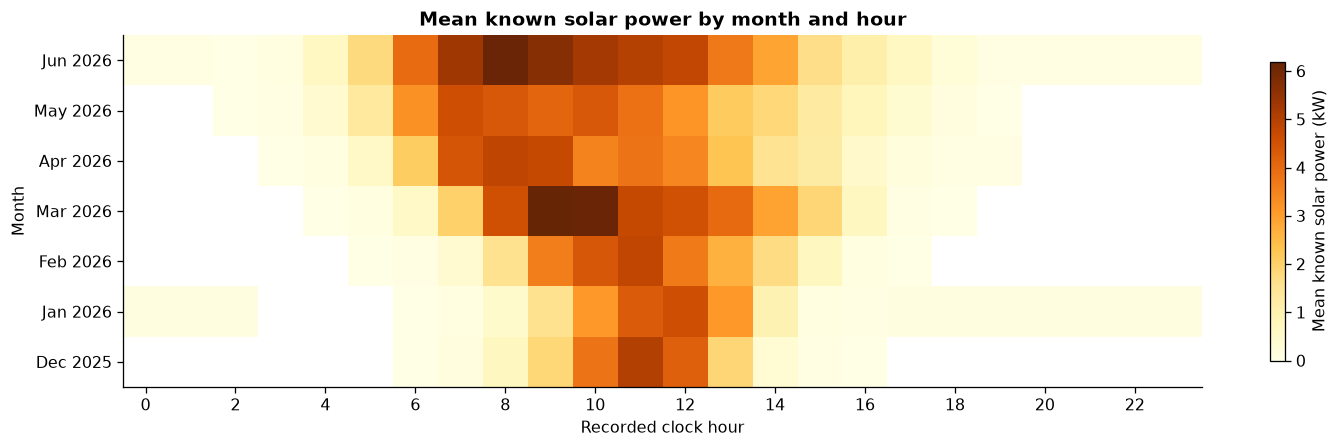

In [7]:
month_labels = minute.raw_minute.dt.strftime("%b %Y")
solar_month_hour = minute.groupby([month_labels, minute.raw_minute.dt.hour]).solar_kw.mean()
month_order = pd.Index(month_labels.drop_duplicates())
solar_heat = solar_month_hour.unstack().reindex(index=month_order, columns=range(24))
fig, ax = plt.subplots(figsize=(13, 4))
im = ax.imshow(solar_heat.to_numpy(), aspect="auto", cmap="YlOrBr", interpolation="nearest",
               origin="lower")
ax.set(title="Mean known solar power by month and hour", xlabel="Recorded clock hour", ylabel="Month")
ax.set_xticks(range(0, 24, 2), range(0, 24, 2))
ax.set_yticks(range(len(solar_heat)), solar_heat.index)
fig.colorbar(im, ax=ax, label="Mean known solar power (kW)", shrink=.85)
fig.tight_layout()
plt.show()

## 5. Battery: charge level and temperature

**State of charge (SoC)** tells us how full the battery is. **Temperature** is a separate sensor. The daily chart below shows the median and the middle 80% of readings on each day. Its band describes the spread **within a day**, not measurement uncertainty.

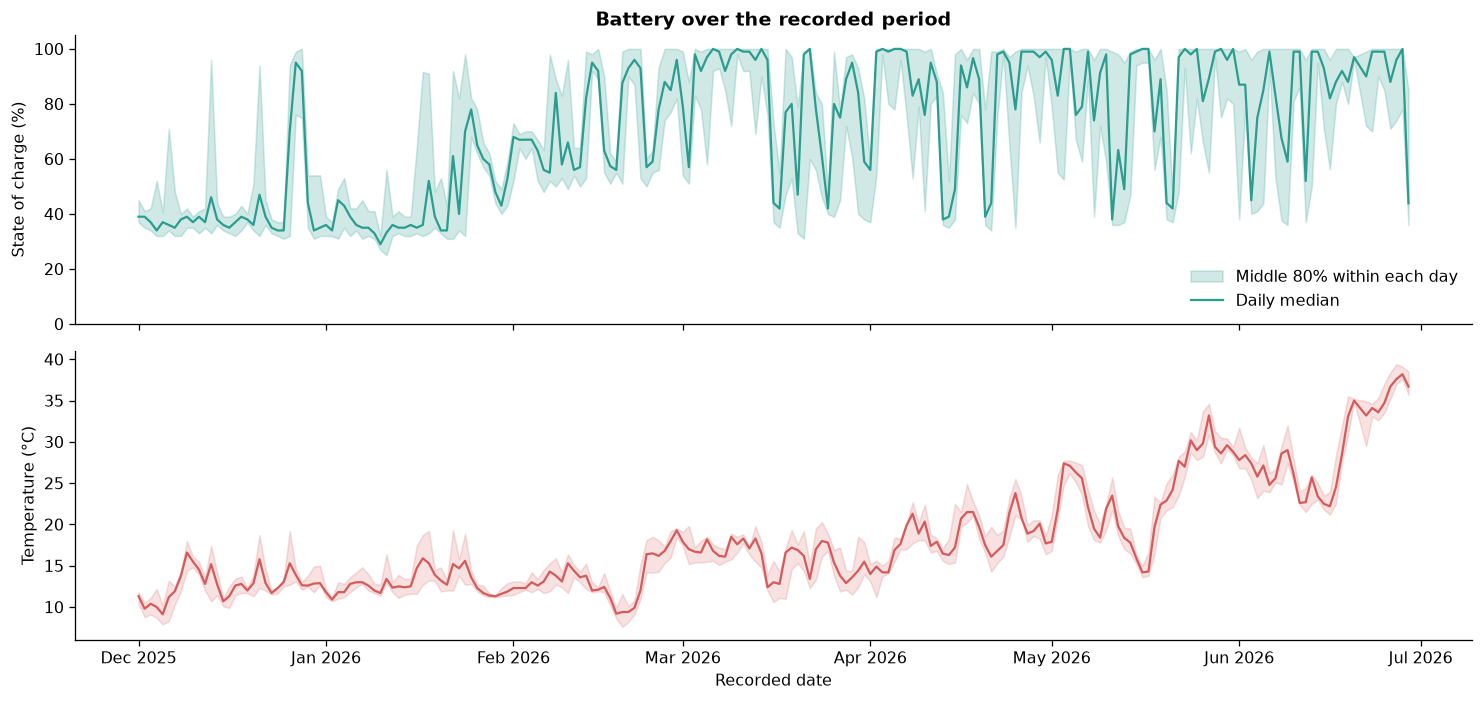

Battery SoC is present in **100.0% of site minutes**. The recorded SoC ranges from **25% to 100%**. Temperature ranges from **7.5°C to 39.5°C**. These ranges alone do not tell us charging efficiency or battery health.

In [8]:
minute["day"] = minute.raw_minute.dt.floor("D")
battery_daily = minute.groupby("day").agg(
    soc_median=("battery_soc_pct", "median"),
    soc_p10=("battery_soc_pct", lambda s: s.quantile(.10)),
    soc_p90=("battery_soc_pct", lambda s: s.quantile(.90)),
    temp_median=("battery_temp_c", "median"),
    temp_p10=("battery_temp_c", lambda s: s.quantile(.10)),
    temp_p90=("battery_temp_c", lambda s: s.quantile(.90)),
)
fig, axes = plt.subplots(2, 1, figsize=(13, 6.2), sharex=True)
axes[0].fill_between(battery_daily.index, battery_daily.soc_p10, battery_daily.soc_p90,
                     color=TEAL, alpha=.22, label="Middle 80% within each day")
axes[0].plot(battery_daily.index, battery_daily.soc_median, color=TEAL, lw=1.4, label="Daily median")
axes[0].set(title="Battery over the recorded period", ylabel="State of charge (%)", ylim=(0, 105))
axes[0].legend(frameon=False, loc="lower right")
axes[1].fill_between(battery_daily.index, battery_daily.temp_p10, battery_daily.temp_p90,
                     color=RED, alpha=.18)
axes[1].plot(battery_daily.index, battery_daily.temp_median, color=RED, lw=1.4)
axes[1].set(ylabel="Temperature (°C)", xlabel="Recorded date")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.tight_layout()
plt.show()
display(Markdown(
    f"Battery SoC is present in **{minute.battery_soc_pct.notna().mean():.1%} of site minutes**. "
    f"The recorded SoC ranges from **{minute.battery_soc_pct.min():.0f}% to "
    f"{minute.battery_soc_pct.max():.0f}%**. Temperature ranges from "
    f"**{minute.battery_temp_c.min():.1f}°C to {minute.battery_temp_c.max():.1f}°C**. "
    "These ranges alone do not tell us charging efficiency or battery health."
))

## 6. EV wallboxes: what was reported?

The eight wallboxes do **not** report power in every site minute. The first chart shows how many wallbox-minute readings are available for each box. The second shows the fraction of **that box's reported minutes** with power above 0.1 kW. That fraction is not its share of total calendar time.

A wallbox that did not report in a minute might have been idle, charging, or disconnected. Its missing reading cannot be filled with zero.

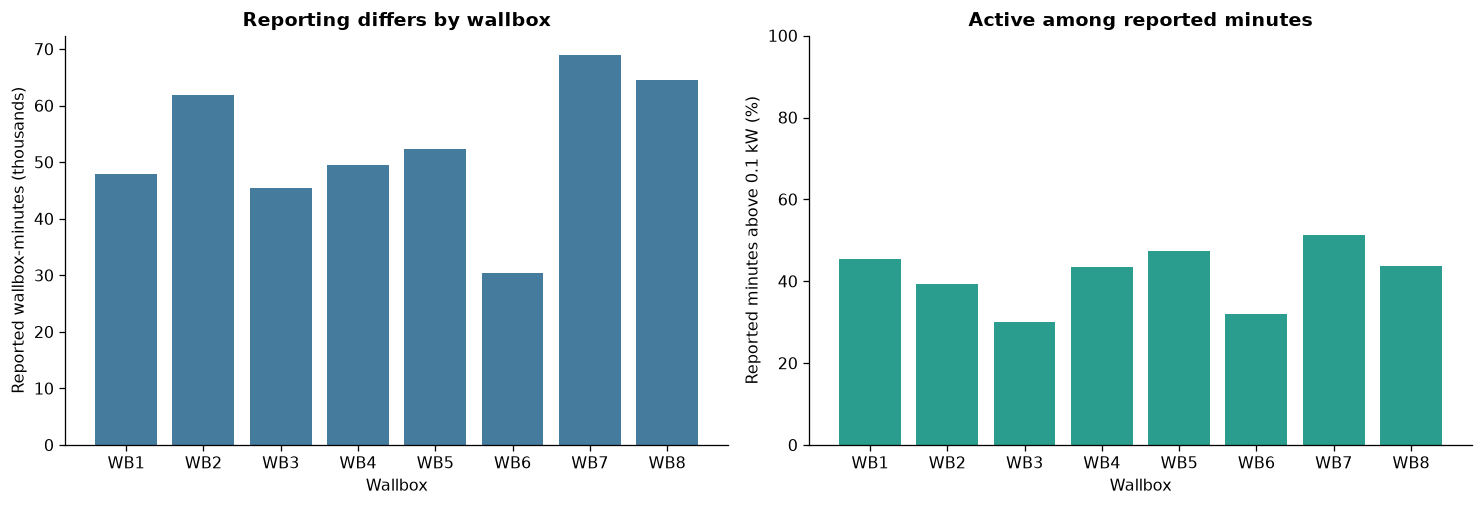

,reported_minutes,active_minutes,active_pct_of_reported,max_reported_kw
wallbox_id,,,,
WB1,"47,887","21,793",45.5%,3.68 kW
WB2,"61,855","24,333",39.3%,3.81 kW
WB3,"45,454","13,617",30.0%,3.82 kW
WB4,"49,550","21,523",43.4%,3.86 kW
WB5,"52,362","24,865",47.5%,3.86 kW
WB6,"30,374","9,727",32.0%,3.81 kW
WB7,"68,931","35,393",51.3%,3.85 kW
WB8,"64,571","28,165",43.6%,3.74 kW


In [9]:
charger["active"] = charger.power_kw > .1
box_summary = charger.groupby("wallbox_id").agg(
    reported_minutes=("raw_minute", "size"),
    active_minutes=("active", "sum"),
    median_reported_kw=("power_kw", "median"),
    max_reported_kw=("power_kw", "max"),
).sort_index()
box_summary["active_pct_of_reported"] = 100 * box_summary.active_minutes / box_summary.reported_minutes
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(box_summary.index, box_summary.reported_minutes / 1000, color=BLUE)
axes[0].set(title="Reporting differs by wallbox", ylabel="Reported wallbox-minutes (thousands)",
            xlabel="Wallbox")
axes[1].bar(box_summary.index, box_summary.active_pct_of_reported, color=TEAL)
axes[1].set(title="Active among reported minutes", ylabel="Reported minutes above 0.1 kW (%)",
            xlabel="Wallbox", ylim=(0, 100))
fig.tight_layout()
plt.show()
display(box_summary[["reported_minutes", "active_minutes", "active_pct_of_reported",
                     "max_reported_kw"]].style.format({
    "reported_minutes": "{:,}", "active_minutes": "{:,}",
    "active_pct_of_reported": "{:.1f}%", "max_reported_kw": "{:.2f} kW"
}).set_caption("Wallbox summary; active means reported power > 0.1 kW"))

### How many boxes report together?

We group wallbox rows by minute. This makes the reporting limit visible. **Observed EV power** is the sum of wallboxes that reported in that minute. It is a complete eight-box total only when all eight reported. We use complete minutes for direct solar-versus-EV comparisons later.

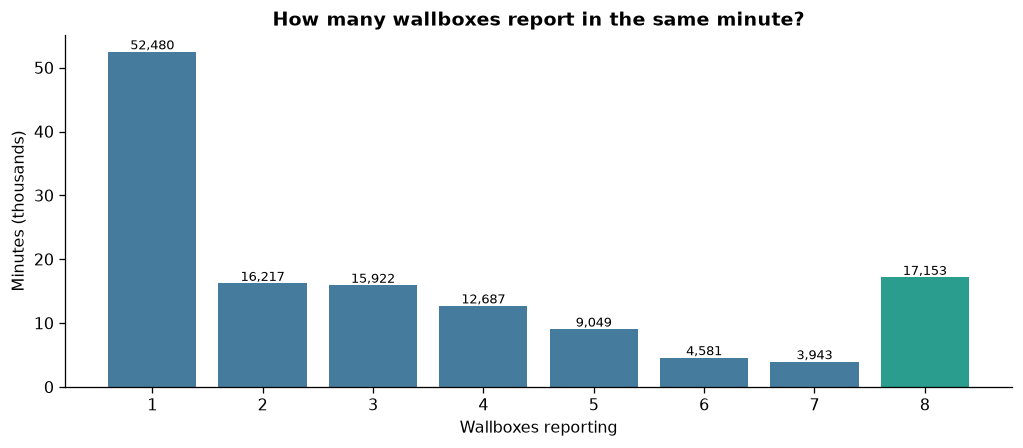

At least one wallbox reports in **132,032 minutes**. All **8** report together in **17,153 minutes**, only **5.6%** of the full first-to-last timeline. A partial sum should not be read as all EV demand.

In [10]:
ev_minute = charger.groupby("raw_minute").agg(
    observed_ev_kw=("power_kw", "sum"),
    reporting_boxes=("wallbox_id", "nunique"),
    active_boxes=("active", "sum"),
)
box_counts = ev_minute.reporting_boxes.value_counts().reindex(range(1, len(wallbox)+1), fill_value=0)
all_box_minutes = int(box_counts.loc[len(wallbox)])
fig, ax = plt.subplots(figsize=(9, 4))
colors = [TEAL if n == len(wallbox) else BLUE for n in box_counts.index]
ax.bar(box_counts.index.astype(str), box_counts.values / 1000, color=colors)
ax.set(title="How many wallboxes report in the same minute?", xlabel="Wallboxes reporting",
       ylabel="Minutes (thousands)")
for i, v in enumerate(box_counts.values):
    ax.text(i, v / 1000 + .4, f"{v:,}", ha="center", fontsize=8)
fig.tight_layout()
plt.show()
display(Markdown(
    f"At least one wallbox reports in **{len(ev_minute):,} minutes**. All **{len(wallbox)}** "
    f"report together in **{all_box_minutes:,} minutes**, only "
    f"**{all_box_minutes / len(full_clock):.1%}** of the full first-to-last timeline. "
    "A partial sum should not be read as all EV demand."
))

## 7. Charging sessions: starts, stops, and duration

A session is built by matching a start with a stop. Session duration includes **time connected**, which may include pauses; it is not the same as time spent drawing power. The start and stop meter registers are kept as raw numbers because their units are not declared here. This notebook does **not** label their difference as kWh.

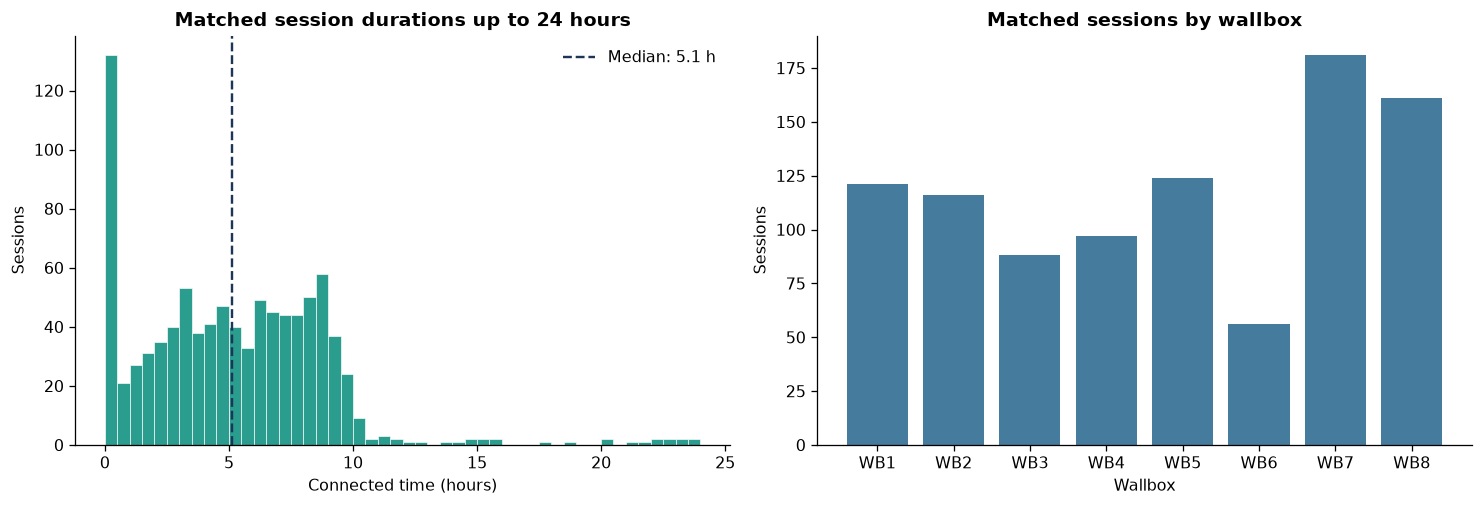

The replay lists **944 session starts**. **943** have a known duration. The median is **5.1 hours**; **14** last over 24 hours and are outside the left chart. A long connected time does not imply continuous charging.

Stop reason,Sessions
EVDisconnected,791
Local,110
Unknown,22
Other,19
PowerLoss,2


In [11]:
session["duration_h"] = (session.stop_raw - session.start_raw).dt.total_seconds() / 3600
valid_duration = session.duration_h.dropna()
short_duration = valid_duration[valid_duration.between(0, 24)]
long_sessions = (valid_duration > 24).sum()
starts_by_box = session.wallbox_id.value_counts().reindex(sorted(wallbox.id), fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(short_duration, bins=np.arange(0, 24.5, .5), color=TEAL, edgecolor="white", lw=.4)
axes[0].axvline(valid_duration.median(), ls="--", color=NAVY,
                label=f"Median: {valid_duration.median():.1f} h")
axes[0].set(title="Matched session durations up to 24 hours", xlabel="Connected time (hours)",
            ylabel="Sessions")
axes[0].legend(frameon=False)
axes[1].bar(starts_by_box.index, starts_by_box.values, color=BLUE)
axes[1].set(title="Matched sessions by wallbox", xlabel="Wallbox", ylabel="Sessions")
fig.tight_layout()
plt.show()
display(Markdown(
    f"The replay lists **{len(session):,} session starts**. **{len(valid_duration):,}** have "
    f"a known duration. The median is **{valid_duration.median():.1f} hours**; "
    f"**{long_sessions:,}** last over 24 hours and are outside the left chart. "
    "A long connected time does not imply continuous charging."
))
display(session.stop_reason.fillna("Unknown").value_counts().rename_axis("Stop reason")
        .reset_index(name="Sessions").style.hide(axis="index"))

## 8. Connector events and faults

These are **event counts**, not minutes spent in each state. Many Charging events do not mean charging happened for longer than another state. A Faulted event marks a change to that state; it does not measure outage duration. Error codes are retained exactly as reported, including cases where simultaneous codes were joined with ` | `.

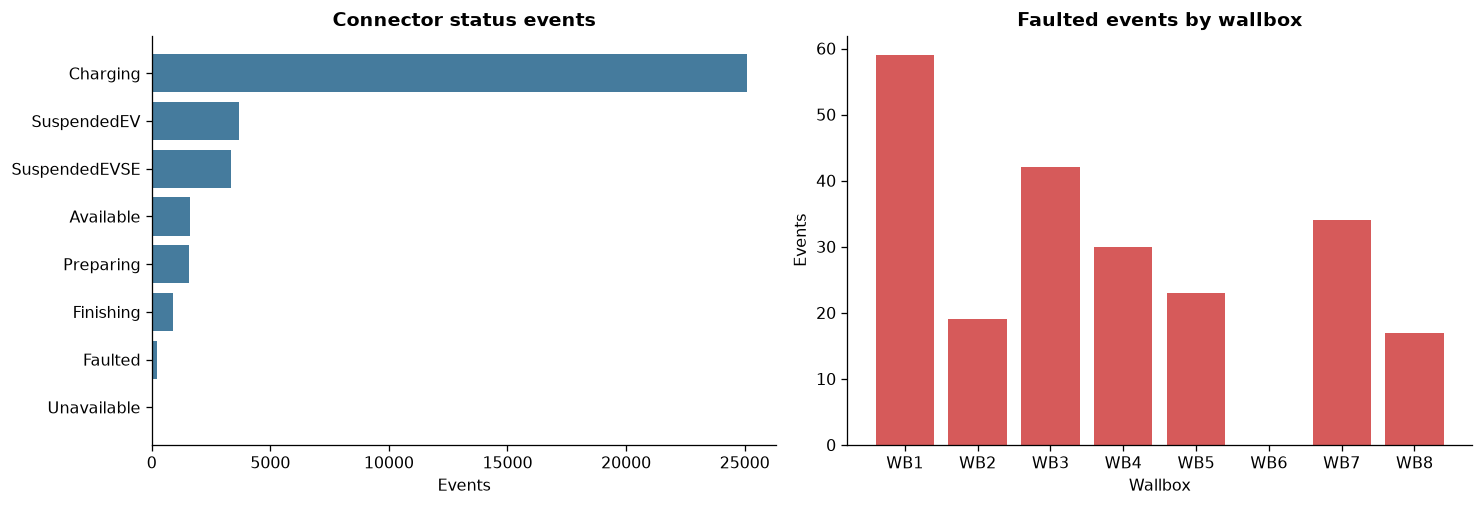

There are **36,421 status events**, including **224 Faulted events**. The most common event state is **Charging**. Event frequency should not be read as time in a state.

In [12]:
status_counts = event.status.value_counts()
fault_by_box = event.loc[event.status.eq("Faulted")].wallbox_id.value_counts().reindex(
    sorted(wallbox.id), fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].barh(status_counts.index[::-1], status_counts.values[::-1], color=BLUE)
axes[0].set(title="Connector status events", xlabel="Events")
axes[1].bar(fault_by_box.index, fault_by_box.values, color=RED)
axes[1].set(title="Faulted events by wallbox", xlabel="Wallbox", ylabel="Events")
fig.tight_layout()
plt.show()
display(Markdown(
    f"There are **{len(event):,} status events**, including **{status_counts.get('Faulted', 0):,} "
    "Faulted events**. The most common event state is **"
    f"{status_counts.index[0]}**. Event frequency should not be read as time in a state."
))

## 9. Putting solar, EV charging, and battery readings together

The next chart shows the **last recorded day** as an example. It is a view of one day, not a typical day. Solar power and battery SoC come from site readings. EV power is the sum of **reporting** wallboxes. The bottom panel shows how many reported, so you can see when the EV line is partial. We leave EV power blank when no wallbox reported.

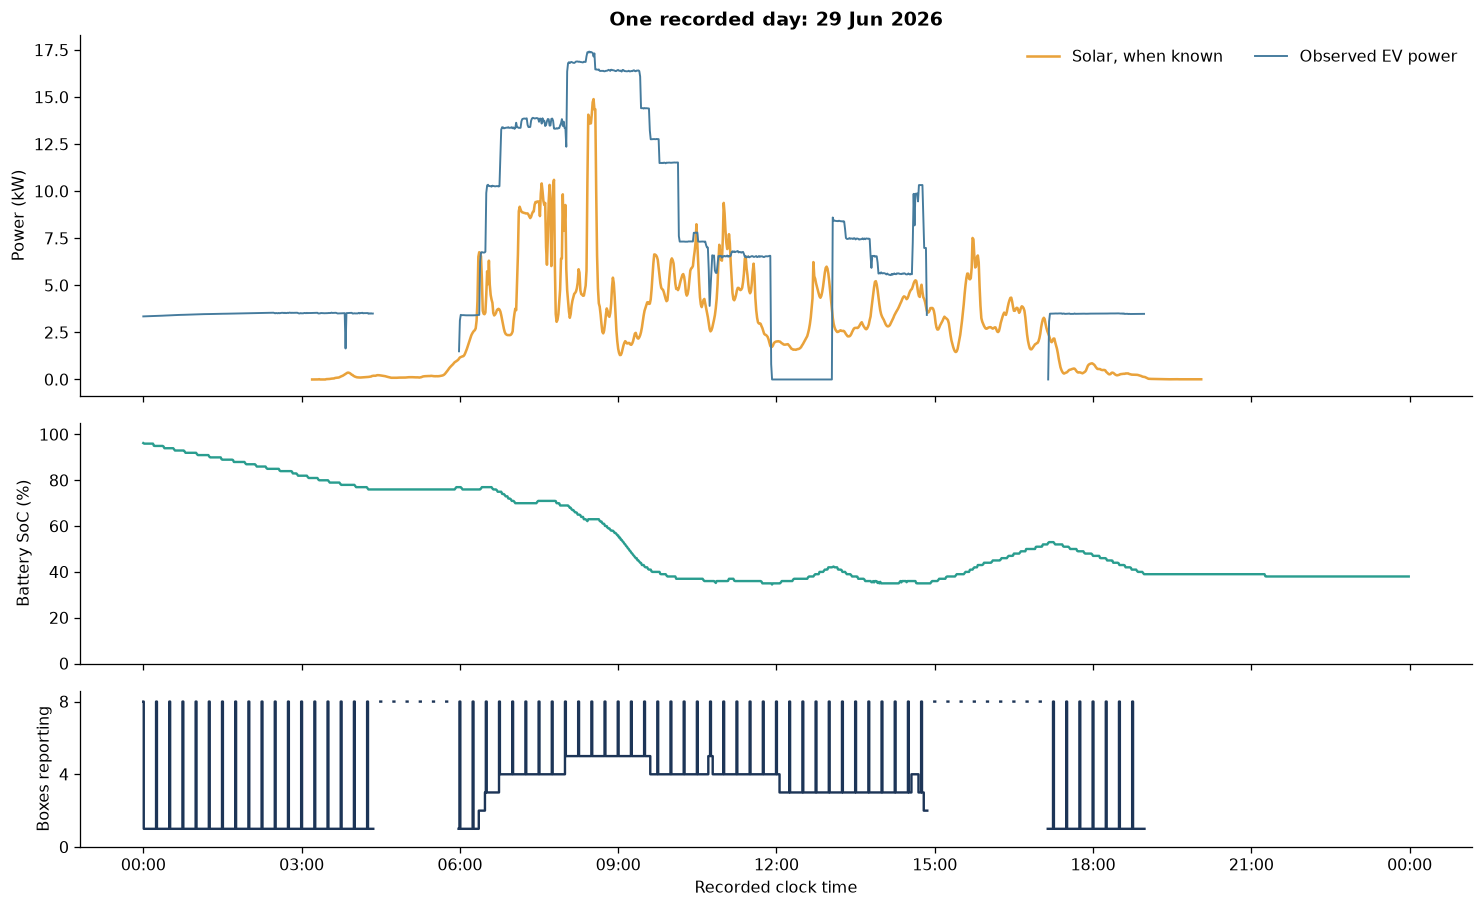

In [13]:
example_day = minute.raw_minute.max().floor("D")
example_minutes = minute.loc[minute.day.eq(example_day),
                             ["raw_minute", "solar_kw", "battery_soc_pct"]].set_index("raw_minute")
example = example_minutes.join(ev_minute[["observed_ev_kw", "reporting_boxes"]])
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True,
                         gridspec_kw={"height_ratios": [1.5, 1, .65]})
axes[0].plot(example.index, example.solar_kw, color=GOLD, label="Solar, when known", lw=1.6)
axes[0].plot(example.index, example.observed_ev_kw, color=BLUE, label="Observed EV power", lw=1.2)
axes[0].set(title=f"One recorded day: {example_day:%d %b %Y}", ylabel="Power (kW)")
axes[0].legend(frameon=False, ncol=2)
axes[1].plot(example.index, example.battery_soc_pct, color=TEAL, lw=1.5)
axes[1].set(ylabel="Battery SoC (%)", ylim=(0, 105))
axes[2].step(example.index, example.reporting_boxes, where="mid", color=NAVY)
axes[2].set(ylabel="Boxes reporting", xlabel="Recorded clock time", ylim=(0, len(wallbox)+.6),
            yticks=[0, 4, len(wallbox)])
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
fig.tight_layout()
plt.show()

### Where a direct solar-versus-EV comparison is possible

Here we use only minutes with **a known solar value and readings from all eight wallboxes**. Each dot represents a minute. Color shows how many dots fall in an area. This is a limited subset of the period, so the shape describes the observed overlap. It does not prove that solar caused a change in charging, or that the site met all loads.

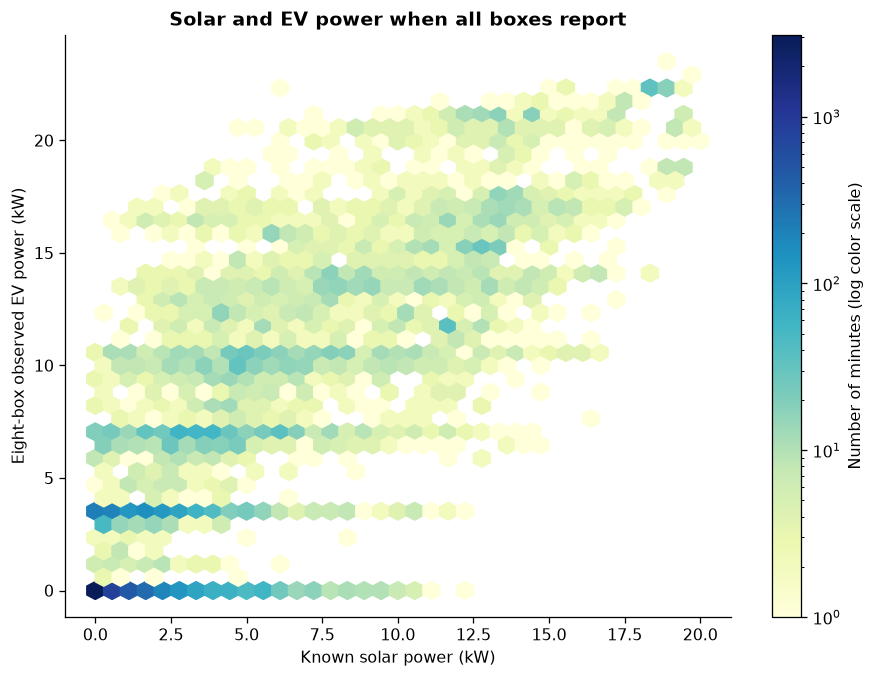

Only **10,334 minutes** (3.4% of the full timeline) meet both conditions. The scatter is useful for seeing joint patterns, but not for estimating total site demand or a causal relationship.

In [14]:
paired = minute[["raw_minute", "solar_kw"]].merge(ev_minute, left_on="raw_minute",
                                                   right_index=True, how="left")
complete = paired.loc[paired.solar_kw.notna() & paired.reporting_boxes.eq(len(wallbox))]
fig, ax = plt.subplots(figsize=(8, 6))
if not complete.empty:
    h = ax.hexbin(complete.solar_kw, complete.observed_ev_kw, gridsize=36,
                  mincnt=1, cmap="YlGnBu", bins="log")
    fig.colorbar(h, ax=ax, label="Number of minutes (log color scale)")
ax.set(title="Solar and EV power when all boxes report", xlabel="Known solar power (kW)",
       ylabel="Eight-box observed EV power (kW)")
fig.tight_layout()
plt.show()
display(Markdown(
    f"Only **{len(complete):,} minutes** ({len(complete) / len(full_clock):.1%} of the "
    "full timeline) meet both conditions. The scatter is useful for seeing joint "
    "patterns, but not for estimating total site demand or a causal relationship."
))

## 10. Data quality: known issues and safe conclusions

The replay builder records checks rather than hiding them. The table below is the exact quality summary for this pinned source. Counts have **different meanings**: some count raw samples, some events, and some session IDs. They should not be added together.

In [15]:
display(quality.sort_values("code").style.format({"count": "{:,}"}).hide(axis="index"))

code,count,detail
conflicting_status_events,50,"Concurrent status error codes preserved as a sorted, pipe-separated set"
duplicate_stop_ids,3,Latest stop timestamp retained per transaction ID
invalid_battery_soc,0,bat_soc outside 0–100% or nonnumeric
invalid_charger_power,0,Power.Active.Import outside 0–100 kW or nonnumeric
invalid_solar_power,0,p_actual outside 0–100 kW or nonnumeric
missing_solar_samples,"1,719,844",Null or JSON 'None' is unknown; nighttime gaps are not converted to zero
open_sessions,1,Starts with no matching stop in this file
unmatched_stop_ids,17,Stops without a start in this JSON period; no session is invented


### What we can say after this EDA

1. **The time span is real, but the filename is slightly broader.** Site readings end on 29 June 2026. The chart in section 3 shows the actual minute coverage.
2. **Solar data has a strong daily and seasonal shape.** The known readings are often absent at night. Treat those gaps as unknown.
3. **Battery SoC and temperature are well covered.** Their changes can be described over time, but battery health and efficiency need more evidence.
4. **EV power coverage is uneven across wallboxes and time.** A sum of reported wallboxes is often only a partial view of EV demand. Use the reporting-count chart before interpreting it.
5. **Session records and connector events answer different questions.** Session durations are connected time. Status charts count events, not time in a status.
6. **Several tempting calculations are not supported.** We do not derive grid imports, full energy balance, charger energy from raw session register differences, weather effects, or total demand when wallboxes are missing.

**Useful next work:** confirm the source clock's time zone and the session meter units with the data owner; investigate missing charger reporting; and validate the physical meaning of `P_sum` before attempting a full site balance. The raw field guide and detailed provenance rules are in `docs/data-pipeline.md`.